# Лінійна регресія: перенавчання і регуляризація

У цьому завданні ми на прикладах побачимо, як перенавчаються лінійні моделі, розберемо, чому так відбувається, і з'ясуємо, як діагностувати та контролювати перенавчання.

В усіх комірках, де вказаний коментар з інструкціями, потрібно написати код, який виконує ці інструкції. Решту комірок із кодом (без коментарів) треба просто виконати. Крім того, у завданні необхідно відповідати на запитання; відповіді потрібно вписувати після виділеного слова "__Відповідь:__".

In [44]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

Ми будемо працювати з датасетом __"bikes_rent.csv"__, у якому по днях записані календарна інформація та погодні умови, що характеризують автоматизовані пункти прокату велосипедів, а також кількість прокатів у цей день. Останнє ми будемо передбачати; таким чином, ми будемо розв'язувати завдання регресії.

### Ознайомлення з даними

## Завдання 1

Завантажте датасет за допомогою функції __pandas.read_csv__ у змінну __df__. Виведіть перші 5 рядків, щоб переконатися в коректному зчитуванні даних:

In [45]:
df = pd.read_csv('bikes_rent.csv')
df.head()

,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed(mph),windspeed(ms),cnt
0,1,0,1,0,6,0,2,14.110847,18.18125,80.5833,10.749882,4.805490,985
1,1,0,1,0,0,0,2,14.902598,17.68695,69.6087,16.652113,7.443949,801
2,1,0,1,0,1,1,1,8.050924,9.47025,43.7273,16.636703,7.437060,1349
3,1,0,1,0,2,1,1,8.200000,10.60610,59.0435,10.739832,4.800998,1562
4,1,0,1,0,3,1,1,9.305237,11.46350,43.6957,12.522300,5.597810,1600


Для кожного дня прокату відомі такі ознаки:
* _season_: 1 — весна, 2 — літо, 3 — осінь, 4 — зима
* _yr_: 0 — 2011, 1 — 2012
* _mnth_: від 1 до 12
* _holiday_: 0 — немає свята, 1 — є свято
* _weekday_: від 0 до 6
* _workingday_: 0 — неробочий день, 1 — робочий день
* _weathersit_: оцінка сприятливості погоди від 1 (чистий, ясний день) до 4 (злива, туман)
* _temp_: температура в Цельсіях
* _atemp_: температура за відчуттями в Цельсіях
* _hum_: вологість
* _windspeed(mph)_: швидкість вітру в милях за годину
* _windspeed(ms)_: швидкість вітру в метрах за секунду
* _cnt_: кількість орендованих велосипедів (це цільова ознака, її ми будемо передбачати)

Отже, у нас є речові, бінарні та номінальні (порядкові) ознаки, і з усіма з них можна працювати як з речовими. З номінальними ознаками теж можна працювати як з речовими, тому що на них заданий порядок. Давайте подивимося на графіках, як цільова ознака залежить від решти.

Побудуйте графіки залежностей атрибутів від кількості поїздок. Іншими словами, вам потрібно побудувати 12 графіків. На кожному має бути зображена залежність чергового атрибута від змінної **cnt**.

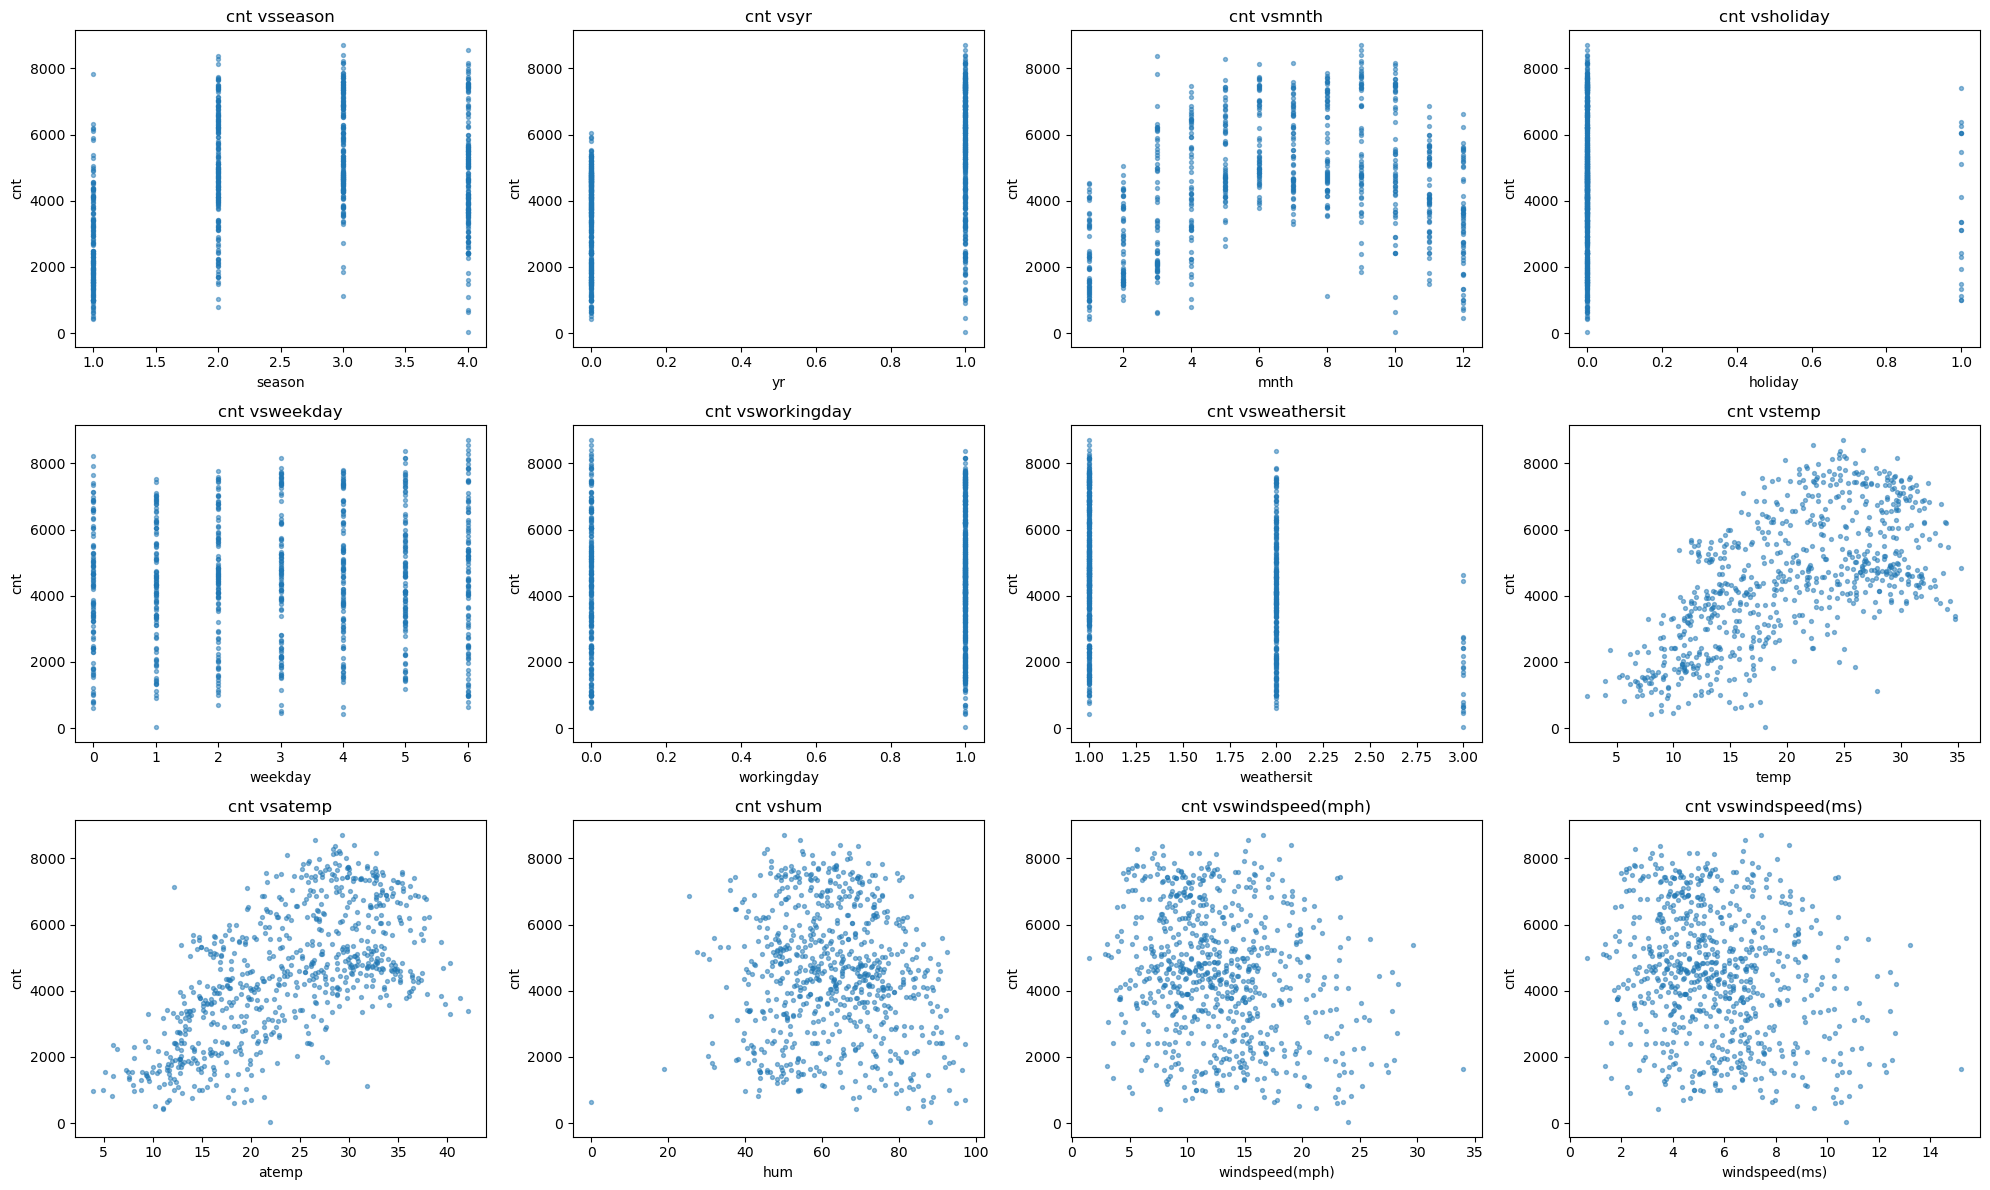

In [46]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, feature in zip(axes.ravel(), df.columns[:-1]):
    ax.scatter(df[feature], df['cnt'], s=8, alpha=0.5)
    ax.set_xlabel(feature)
    ax.set_ylabel('cnt')
    ax.set_title('cnt vs' + feature)
plt.tight_layout()
plt.show()

__Запитання:__
1. Яким є характер залежності кількості прокатів від місяця?
1. Вкажіть одну або дві ознаки, від яких кількість прокатів скоріше за все залежить лінійно.

__Відповідь:__
1. Залежність від місяця нелінійна: з січня кількість прокатів зростає, досягає максимуму влітку та на початку осені, 
а потім знову падає до зими
1. Від 'cnt' залежить температура охнаки 'temp'та 'atemp' точки на графіку групуються навколо зростаючої прямої
   (коеф.кореляції приблизно =0.63)

## Завдання 2

Давайте більш строго оцінимо рівень лінійної залежності між ознаками та цільовою змінною. Гарною мірою лінійної залежності між двома векторами є кореляція Пірсона. Нам уже доводилося мати з нею справу раніше. Для її обчислення в pandas можна використовувати методи датафрейму: corr і corrwith.

Порахуйте кореляції всіх ознак, окрім останньої, з останньою за допомогою методу `corrwith`.

In [47]:
df.drop('cnt', axis=1).corrwith(df['cnt'])

season            0.406100
yr                0.566710
mnth              0.279977
holiday          -0.068348
weekday           0.067443
workingday        0.061156
weathersit       -0.297391
temp              0.627494
atemp             0.631066
hum              -0.100659
windspeed(mph)   -0.234545
windspeed(ms)    -0.234545
dtype: float64

У вибірці є ознаки, що корелюють із цільовою, а отже, завдання можна розв'язувати лінійними методами.

За графіками видно, що деякі ознаки схожі між собою. Тому давайте також порахуємо кореляції між речовими ознаками.

## Завдання 3

Порахуйте попарні кореляції між ознаками temp, atemp, hum, windspeed(mph), windspeed(ms) і cnt
за допомогою методу corr:

In [48]:
df[['temp', 'atemp', 'hum', 'windspeed(mph)', 'windspeed(ms)', 'cnt']].corr()

,temp,atemp,hum,windspeed(mph),windspeed(ms),cnt
temp,1.000000,0.991702,0.126963,-0.157944,-0.157944,0.627494
atemp,0.991702,1.000000,0.139988,-0.183643,-0.183643,0.631066
hum,0.126963,0.139988,1.000000,-0.248489,-0.248489,-0.100659
windspeed(mph),-0.157944,-0.183643,-0.248489,1.000000,1.000000,-0.234545
windspeed(ms),-0.157944,-0.183643,-0.248489,1.000000,1.000000,-0.234545
cnt,0.627494,0.631066,-0.100659,-0.234545,-0.234545,1.000000


На діагоналях, як і належить, стоять одиниці. Однак у матриці є ще дві пари сильно корелюючих стовпців: temp і atemp (корелюють за своєю природою) і два windspeed (тому що це просто переведення одних одиниць в інші). Далі ми побачимо, що цей факт негативно позначається на навчанні лінійної моделі.

Насамкінець подивимося середні ознак (метод mean), щоб оцінити масштаб ознак і частки 1 у бінарних ознак.

## Завдання 4

Виведіть середні ознак.

In [49]:
df.mean()

season               2.496580
yr                   0.500684
mnth                 6.519836
holiday              0.028728
weekday              2.997264
workingday           0.683995
weathersit           1.395349
temp                20.310776
atemp               23.717699
hum                 62.789406
windspeed(mph)      12.762576
windspeed(ms)        5.705220
cnt               4504.348837
dtype: float64

Ознаки мають різний масштаб, отже, для подальшої роботи нам краще нормувати матрицю об'єкти-ознаки.

### Проблема перша: колінеарні ознаки

Отже, у наших даних одна ознака дублює іншу, і є ще дві дуже схожі. Звичайно, ми могли б одразу видалити дублікати, але давайте подивимося, як відбувалося б навчання моделі, якби ми не помітили цю проблему.

Для початку проведемо масштабування, або стандартизацію ознак: з кожної ознаки віднімемо її середнє і поділимо на стандартне відхилення. Це можна зробити за допомогою методу scale.

Крім того, необхідно перемішати вибірку, це буде потрібно для крос-валідації.

In [50]:
from sklearn.preprocessing import scale
from sklearn.utils import shuffle

In [51]:
df_shuffled = shuffle(df, random_state=42)
X = scale(df_shuffled[df_shuffled.columns[:-1]])
y = df_shuffled["cnt"]

Давайте навчимо лінійну регресію на наших даних і подивимося на ваги ознак.

In [52]:
from sklearn.linear_model import LinearRegression

## Завдання 5

Створіть об'єкт лінійного регресора, навчіть його на всіх даних і виведіть ваги моделі (ваги зберігаються у змінній `coef_` класу регресора). Можна виводити пари (назва ознаки, вага), скориставшись функцією `zip`, вбудованою в мову python. Назви ознак зберігаються у змінній `df.columns`.


In [53]:
lin_reg = LinearRegression()
lin_reg.fit(X, y)
for feature, coef in zip(df.columns, lin_reg.coef_):
    print('{}: {}'.format(feature, coef))

season: 570.8693632797535
yr: 1021.9721595813337
mnth: -141.30453962011194
holiday: -86.75560531762187
weekday: 137.22411258841313
workingday: 56.39410303666908
weathersit: -330.23169353156516
temp: 367.46777184245224
atemp: 585.5635179675158
hum: -145.60536461872516
windspeed(mph): 12461619843411.346
windspeed(ms): -12461619843609.797


Ми бачимо, що ваги при лінійно-залежних ознаках за модулем значно більші, ніж при інших ознаках. Щоб зрозуміти, чому так сталося, згадаємо аналітичну формулу, за якою обчислюються ваги лінійної моделі в методі найменших квадратів:

$$w = (X^TX)^{-1} X^T y$$

Якщо в $X$ є колінеарні (лінійно-залежні) стовпці, матриця $X^TX$ стає виродженою, і формула перестає бути коректною. Чим більш залежні ознаки, тим менший визначник цієї матриці й тим гірша апроксимація $Xw \approx y$. Таку ситуацію називають _проблемою мультиколінеарності_.

З парою (temp, atemp) трохи менше корелюючих змінних такого не сталося, однак на практиці завжди варто уважно стежити за коефіцієнтами при схожих ознаках.

Для того щоб розв'язати проблему мультиколінеарності, потрібно скористатися регуляризатором. До оптимізуючого функціоналу додають $L_1$ або $L_2$ норму ваг, помножену на коефіцієнт регуляризації $\alpha$. У першому випадку метод називається Lasso, а у другому — Ridge.

### Завдання 6
Давайте спробуємо навчити лінійні моделі з $L_1$ і $L_2$-регуляризацією, а далі порівняємо їхні ваги. Навчіть регресори Ridge і Lasso з параметрами за замовчуванням і переконайтеся, що проблема з вагами вирішилась.

Навчіть лінійну модель з $L_1$-регуляризацією (клас Lasso) і виведіть ваги.

In [54]:
from sklearn.linear_model import Lasso, Ridge

lasso = Lasso()
lasso.fit(X, y)
for feature, coef in zip(df.columns, lasso.coef_):
    print('{}: {}'.format(feature, coef))

season: 560.2416160308869
yr: 1019.4634940657199
mnth: -128.73062703678747
holiday: -86.15278133371096
weekday: 137.34789390496323
workingday: 55.2123706413565
weathersit: -332.3698569623486
temp: 376.3632362096933
atemp: 576.5307935045561
hum: -144.1291550034859
windspeed(mph): -197.13968940248316
windspeed(ms): -2.8052211033484374e-08


Навчіть лінійну модель з $L_2$-регуляризацією (клас Ridge) і виведіть ваги.

In [55]:
ridge = Ridge()
ridge.fit(X, y)
for feature, coef in zip(df.columns, ridge.coef_):
    print('{}: {}'.format(feature, coef))

season: 563.0645722520179
yr: 1018.9483787875291
mnth: -131.8733202824774
holiday: -86.74609799709216
weekday: 138.00511117871915
workingday: 55.90311037506469
weathersit: -332.349788499074
temp: 386.45788919193006
atemp: 566.3470470600448
hum: -145.07132729867152
windspeed(mph): -99.25944108184231
windspeed(ms): -99.25944115429066


### Завдання 7

На відміну від $L_2$-регуляризації, $L_1$ обнуляє ваги при деяких ознаках. Давайте поспостерігаємо, як змінюються ваги зі збільшенням коефіцієнта регуляризації $\alpha$.

Для кожного значення коефіцієнта з `alphas` навчіть регресор `Lasso` і запишіть ваги у список `coefs_lasso`, а потім навчіть `Ridge` і запишіть ваги у список`coefs_ridge`. Конвертуйте отримані списки в `np.array`.

In [56]:
alphas = np.arange(1, 500, 50)

coefs_lasso = []
coefs_ridge = []

for alpha in alphas:
    coefs_lasso.append(Lasso(alpha=alpha).fit(X, y).coef_)
    coefs_ridge.append(Ridge(alpha=alpha).fit(X, y).coef_)

coefs_lasso = np.array(coefs_lasso)
coefs_ridge = np.array(coefs_ridge)

Проаналізуйте динаміку ваг при збільшенні параметра регуляризації:

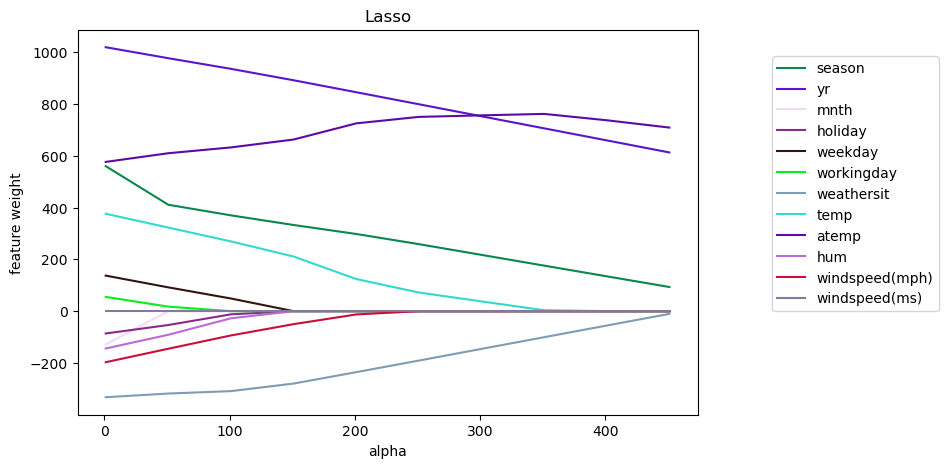

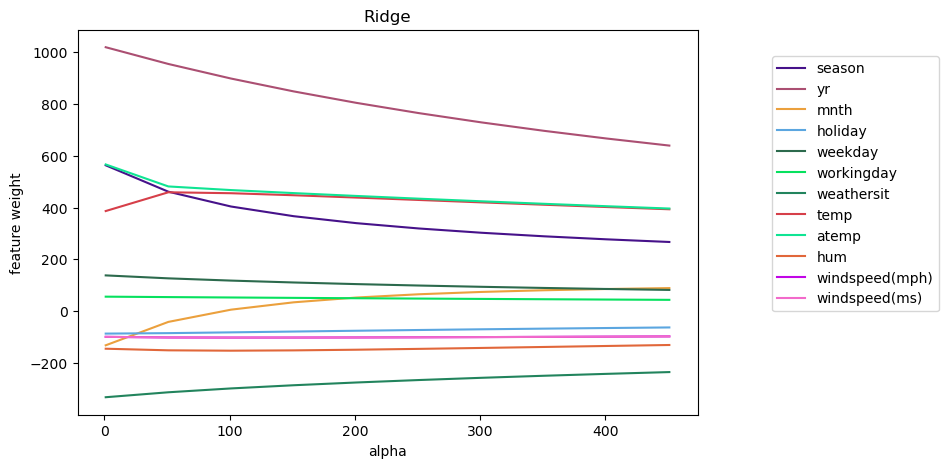

In [57]:
plt.figure(figsize=(8, 5))

for coef, feature in zip(coefs_lasso.T, df.columns):
    plt.plot(alphas, coef, label=feature, color=np.random.rand(3))

plt.legend(loc="upper right", bbox_to_anchor=(1.4, 0.95))
plt.xlabel("alpha")
plt.ylabel("feature weight")
plt.title("Lasso")

plt.figure(figsize=(8, 5))
for coef, feature in zip(coefs_ridge.T, df.columns):
    plt.plot(alphas, coef, label=feature, color=np.random.rand(3))

plt.legend(loc="upper right", bbox_to_anchor=(1.4, 0.95))
plt.xlabel("alpha")
plt.ylabel("feature weight")
plt.title("Ridge")

plt.show()

Проаналізуйте графіки та дайте відповіді на такі запитання.

1. Який регуляризатор (Ridge або Lasso) агресивніше зменшує ваги при одному й тому самому alpha?
1. Що станеться з вагами Lasso, якщо alpha зробити дуже великим? Поясніть, чому так відбувається.
1. Чи можна стверджувати, що `Lasso` виключає одну з ознак `windspeed` при будь-якому значенні `alpha > 0`? А Ridge? Вважається, що регуляризатор виключає ознаку, якщо коефіцієнт при ньому менший $10^{-3}$.
1. Який із регуляризаторів підійде для відбору неінформативних ознак?

__Відповідь:__
1. Агресивніше ваги зменшує Lasso: при `alpha = 451` він уже обнулив 8 з 12 ознак, тоді як Ridge лише плавно зменшує всі ваги, і жодна з них не доходить до нуля.
2. При дуже великому `alpha` усі ваги Lasso стануть рівними нулю. Штраф $\alpha \sum |w_j|$ починає переважати над помилкою, і оптимально вимкнути всі ознаки; модель перетворюється на константу, що дорівнює середньому значенню `cnt`.
3. У нашому експерименті `Lasso` обнуляє `windspeed(ms)` при кожному `alpha` із сітки, а вагу отримує `windspeed(mph)`: ознаки збігаються з точністю до масштабу, тож з погляду штрафу немає різниці, яку з них залишити. Строго стверджувати це для будь-якого `alpha > 0` не можна: при ідеальній колінеарності розв'язок Lasso не єдиний, а вибір ознаки залежить від алгоритму оптимізації. Ridge ознаку не виключає: ваги `windspeed(mph)` і `windspeed(ms)` завжди однакові і за модулем значно більші за $10^{-3}$, штраф просто ділить вагу порівну між дублями.
4. Для відбору неінформативних ознак підходить Lasso ($L_1$-регуляризація), бо вона обнуляє ваги.

### Завдання 8

Далі будемо працювати з `Lasso`.

Отже, ми бачимо, що при зміні alpha модель по-різному підбирає коефіцієнти ознак. Нам потрібно вибрати найкраще alpha.

Для цього, по-перше, нам потрібна метрика якості. Будемо використовувати як метрику сам оптимізований функціонал методу найменших квадратів, тобто `Mean Square Error`.

По-друге, потрібно зрозуміти, на яких даних цю метрику рахувати. Не можна вибирати `alpha` за значенням MSE на навчальній вибірці, тому що тоді ми не зможемо оцінити, як модель буде робити передбачення на нових для неї даних. Якщо ми виберемо одне розбиття вибірки на навчальну та тестову (це називається holdout), то налаштуємося на конкретні "нові" дані, і знову можемо перенавчитися. Тому будемо робити декілька розбиттів вибірки, на кожному пробувати різні значення alpha, а потім усереднювати MSE. Найзручніше робити такі розбиття крос-валідацією, тобто розділити вибірку на $K$ частин, і кожного разу брати одну з них як тестову, а з блоків, що залишилися, складати навчальну вибірку.

Робити крос-валідацію для регресії в sklearn зовсім просто: для цього є спеціальний регресор, __LassoCV__, який бере на вхід список із alpha і для кожного з них обчислює MSE на крос-валідації. Після навчання (якщо залишити параметр cv=3 за замовчуванням) регресор буде містити змінну __mse\_path\___, матрицю розміру len(alpha) x k, k = 3 (число блоків у крос-валідації), що містить значення MSE на тесті для відповідних запусків. Крім того, у змінній alpha\_ буде зберігатися вибране значення параметра регуляризації, а в coef\_, традиційно, навчені ваги, що відповідають цьому alpha_.

Зверніть увагу, що регресор може змінювати порядок, у якому він проходить по alphas; для зіставлення з матрицею MSE краще використовувати змінну регресора alphas_.

Навчіть регресор `LassoCV` на всіх параметрах регуляризації з alpha. Побудуйте графік _усередненого_ за рядками `MSE` в залежності від `alpha` (використовуйте для цього функцію `create_plot`).

Виведіть вибране `alpha`, а також пари "ознака-коефіцієнт" для навченого вектора коефіцієнтів.

In [61]:
def create_plot(data, title, xlabel, ylabel, figsize=None):
    size = figsize or (15, 5)
    plt.figure(figsize=size)

    x = list(map(lambda e: e[0], data))
    y = list(map(lambda e: e[1], data))
    plt.plot(x, y)

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    plt.grid()
    plt.show()

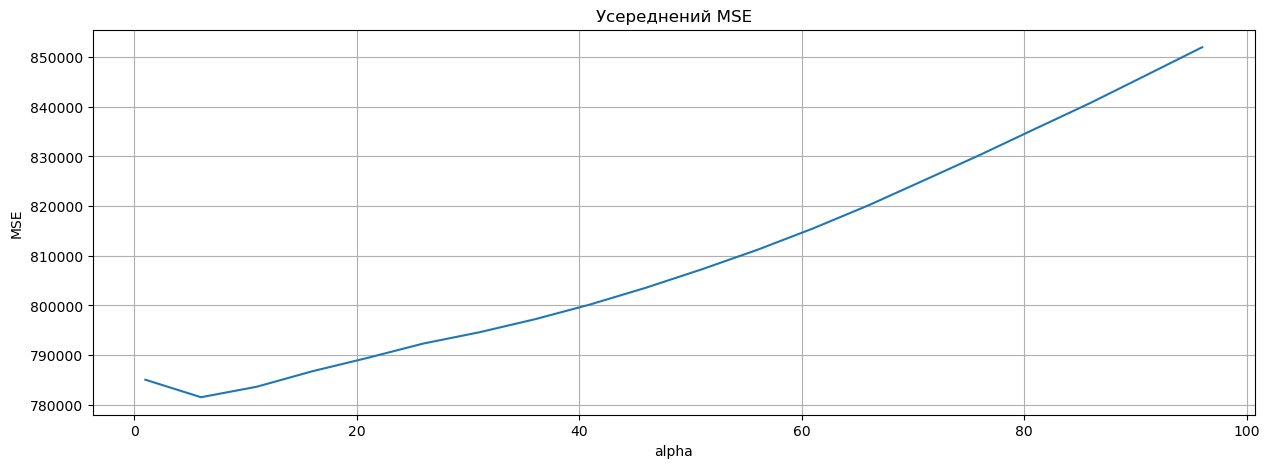

Alpha = 6

season: 532.0189828413535
yr: 1015.0602226430592
mnth: -100.03952614356622
holiday: -83.29395987529924
weekday: 132.50446549095787
workingday: 51.55708561407394
weathersit: -330.55985673998157
temp: 370.679855030032
atemp: 581.3969310654999
hum: -140.0074055006885
windspeed(mph): -191.77140847135084
windspeed(ms): -2.6854222061742536e-08


In [62]:
from sklearn.linear_model import LassoCV

alphas = np.arange(1, 100, 5)

regressor = LassoCV(alphas=alphas, cv=3)
regressor.fit(X, y)

mean_mse = regressor.mse_path_.mean(axis=1)
create_plot(
    sorted(zip(regressor.alphas_, mean_mse)),
    'Усереднений MSE', 
    'alpha', 
    'MSE'
)

print('Alpha = {}\n'.format(regressor.alpha_))

for feature, coef in zip(df.columns, regressor.coef_):
    print('{}: {}'.format(feature, coef))

Отже, ми вибрали певний параметр регуляризації. Давайте подивимося, які б ми вибирали alpha, якби ділили вибірку лише один раз на навчальну та тестову, тобто розглянемо траєкторії MSE, що відповідають окремим блокам вибірки.

### Завдання 9

Виведіть значення `alpha`, що відповідають мінімумам `MSE` на кожному розбитті (тобто за стовпцями).
На трьох окремих графіках візуалізуйте стовпці `mse_path_`.


Alphas with minimum MSE:
Alpha = 6, MSE = 733725.7604052242
Alpha = 1, MSE = 799433.1673691702
Alpha = 51, MSE = 796979.8955193637


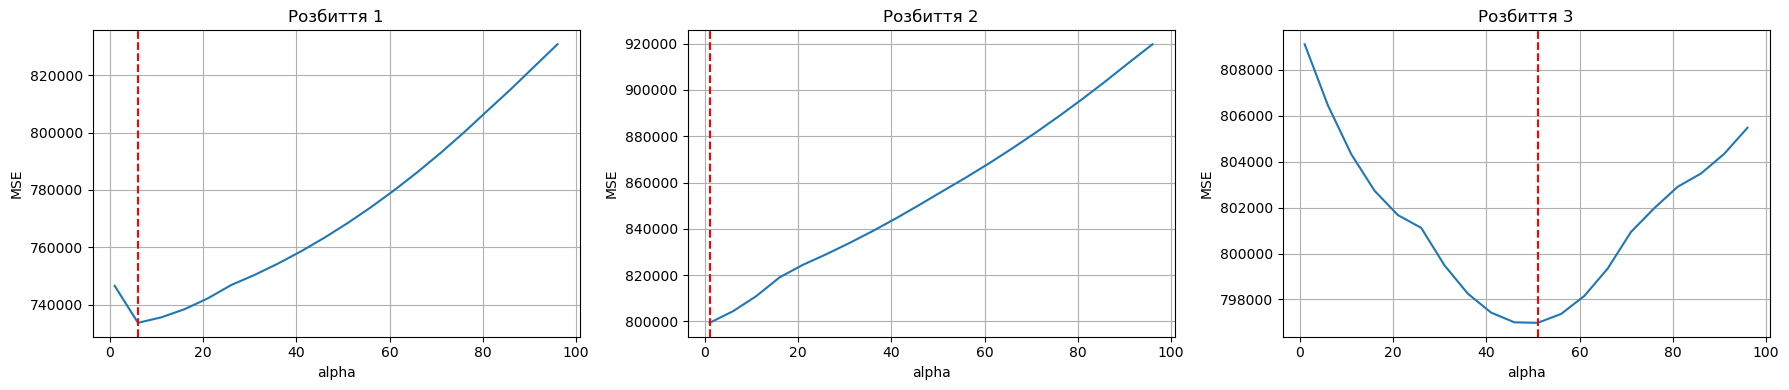

In [63]:
print('Alphas with minimum MSE:')
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for k, ax in enumerate(axes):
    mse_k = regressor.mse_path_[:, k]
    best = np.argmin(mse_k)
    print('Alpha = {}, MSE = {}'.format(regressor.alphas_[best], mse_k[best]))
    order = np.argsort(regressor.alphas_)
    ax.plot(regressor.alphas_[order], mse_k[order])
    ax.axvline(regressor.alphas_[best], color='r', linestyle='--')
    ax.set_title('Розбиття {}'.format(k + 1))
    ax.set_xlabel('alpha')
    ax.set_ylabel('MSE')
    ax.grid()
plt.tight_layout()
plt.show()

На кожному розбитті оптимальне значення `alpha` своє, і йому відповідає велике MSE на інших розбиттях. Виходить, що ми налаштовуємося на конкретні навчальні та контрольні вибірки. При виборі `alpha` на крос-валідації ми вибираємо дещо "середнє", що даватиме прийнятне значення метрики на різних розбиттях вибірки.

### Завдання 10

Нарешті, як прийнято в аналізі даних, давайте проінтерпретуємо результат. Дайте відповіді на наступні запитання.

#### Запитання 1

В останній навченій моделі виберіть 4 ознаки з найбільшими (позитивними) коефіцієнтами (і випишіть їх), подивіться на візуалізації залежностей `cnt` від цих ознак, які ми зображали у блоці "Ознайомлення з даними". Чи видно зростаючу лінійну залежність `cnt` від цих ознак за графіками? Чи логічно стверджувати (виходячи зі здорового глузду), що чим більше значення цих ознак, тим більше людей захочуть взяти велосипеди?

__Відповідь:__
чотири ознаки з найбільшими додатними коефіцієнтами: `yr` (≈ 1015), `atemp` (≈ 581), `season` (≈ 532), `temp` (≈ 371).
- `temp` і `atemp`: на графіках видно зростаючу лінійну залежність: чим тепліше, тим охочіше люди їздять на велосипедах (хоча при дуже високій температурі зростання, ймовірно, припинилося б).
- `yr`: це бінарна ознака (2011/2012), графік показує, що в 2012 році прокатів у середньому більше, тож зростаючий зв'язок є. Але логічно це пояснюється ростом популярності сервісу; екстраполювати на наступні роки не можна.
- `season`: на графіку залежність немає вигляду лінійної зростаючої, кількість прокатів зростає до літа/осені, а до зими знову падає. Позитивний коефіцієнт тут частково компенсує інші ознаки (наприклад, `mnth` з від'ємним коефіцієнтом), тому стверджувати, що зі збільшенням номера сезону попит зростає, нелогічно.

In [66]:
coefs = sorted(zip(df.columns[:-1], regressor.coef_), key=lambda p: -p[1])
print('Найбільші додатні коефіцієнти:')
for name, c in coefs[:4]:
    print('{}: {:.2f}'.format(name, c))

Найбільші додатні коефіцієнти:
yr: 1015.06
atemp: 581.40
season: 532.02
temp: 370.68


#### Запитання 2

Виберіть 3 ознаки з найбільшими за модулем негативними коефіцієнтами (і випишіть їх), подивіться на відповідні візуалізації. Чи видно лінійну залежність, що зменшується? Чи логічно стверджувати, що чим більша величина цих ознак, тим менше людей захочуть взяти велосипеди?

In [68]:
print('Найбільші за модулем від\'ємні коефіцієнти:')
for name, c in sorted(coefs, key=lambda p: p[1])[:3]:
    print('{}: {:.2f}'.format(name, c))

Найбільші за модулем від'ємні коефіцієнти:
weathersit: -330.56
windspeed(mph): -191.77
hum: -140.01


__Відповідь:__

три ознаки з найбільшими за модулем від'ємними коефіцієнтами: `weathersit` (≈ −331), `windspeed(mph)` (≈ −192), `hum` (≈ −140).
- `weathersit`: на графіку видно, що зі збільшенням (погіршенням погоди) кількість прокатів спадає; це логічно: у дощ і туман на велосипедах їздять менше.
- `windspeed(mph)`: спадаюча залежність є, хоч і слабка та шумна (кореляція ≈ −0.23); логічно, адже сильний вітер ускладнює їзду.
- `hum`: спадна лінійна залежність виражена слабко (кореляція ≈ −0.10); з точки зору здорового глузду висока вологість (дощ, спека, туман) відлякує велосипедистів, але вплив невеликий і значною мірою пов'язаний із `weathersit`.

#### Запитання 3

Випишіть ознаки з коефіцієнтами, близькими до нуля (< 1e-3). Як ви думаєте, чому модель виключила їх із моделі (знову подивіться на графіки)? Чи правда, що вони ніяк не впливають на попит на велосипеди?

__Відповідь:__
до нуля близький лише коефіцієнт `windspeed(ms)` (≈ −2.7e-08). Ця ознака є точною копією `windspeed(mph)` в іншому масштабі (кореляція 1), тому не несе додаткової інформації, і Lasso залишає вагу лише в одній із двох ознак. Це не означає, що швидкість вітру не впливає на попит: її вплив (кореляція з `cnt` ≈ −0.23) повністю враховано через `windspeed(mph)`.

In [69]:
print('Ознаки з |коефіцієнтом| < 1e-3:')
for name, c in coefs:
    if abs(c) < 1e-3:
        print('{}: {}'.format(name, c))

Ознаки з |коефіцієнтом| < 1e-3:
windspeed(ms): -2.6854222061742536e-08


### Висновок
Отже, ми подивилися, як можна стежити за адекватністю лінійної моделі, як відбирати ознаки і як грамотно, за можливості не налаштовуючись на якусь конкретну порцію даних, підбирати коефіцієнт регуляризації.

Варто зазначити, що за допомогою крос-валідації зручно підбирати лише невелику кількість параметрів. (1, 2, максимум 3), тому що для кожної допустимої їх комбінації нам доводиться декілька разів навчати модель. Такий процес займає багато часу, особливо якщо треба навчатися на великих обсягах даних.